In [16]:
import numpy as np
import matplotlib.pyplot as plt
def f(x, t):
    return np.tan(x)-t
def df(x):
    return 1/(np.cos(x)**2) 

def newt(x0, target, t, maxIters=10 ): 
    x = x0
    iter = 0
    errors = []
    while iter < maxIters:
        err = abs(x - target)
        errors.append(err)
        fx = f(x, t)
        dfx = df(x)
        x = x - fx / dfx
        iter += 1
    return errors

def secant_method(x0, x1, target, t, maxIters=10):
    errors = []
    iter = 0
    while iter < maxIters:
        err = abs(x0-target)
        errors.append(err)
        fx0 = f(x0, t)
        fx1 = f(x1, t)
        if fx1-fx0 == 0:
            for i in range(0, maxIters-iter-1):
                errors.append(0)
            break
        x_next = x1 - fx1 * (x1 - x0) / (fx1 - fx0)
        x0, x1 = x1, x_next
        iter += 1
    return errors

In [17]:
newt(0.5, np.arctan(0.25), 0.25)

[np.float64(0.2550213368731359),
 np.float64(0.026823632702705075),
 np.float64(0.0001926983622183298),
 np.float64(9.287934865653824e-09),
 np.float64(5.551115123125783e-17),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0)]

In [18]:
secant_method(0.5, 1, np.arctan(0.25), 0.25)

[np.float64(0.2550213368731359),
 np.float64(0.7550213368731359),
 np.float64(0.10849727605213541),
 np.float64(0.04377463956333563),
 np.float64(0.001426384796508945),
 np.float64(1.655042206352708e-05),
 np.float64(5.913172146376766e-09),
 np.float64(2.450817326860033e-14),
 np.float64(0.0),
 0]

In [19]:
newt_err = newt(0.5, np.arctan(0.5), 0.5)

In [20]:
sec_err = secant_method(0.5, 1, np.arctan(0.5), 0.5)

Newtons method is better because it converges quicker, but this is because it is using the derivative to make the next guess which is more effeicent than estimating with secant method

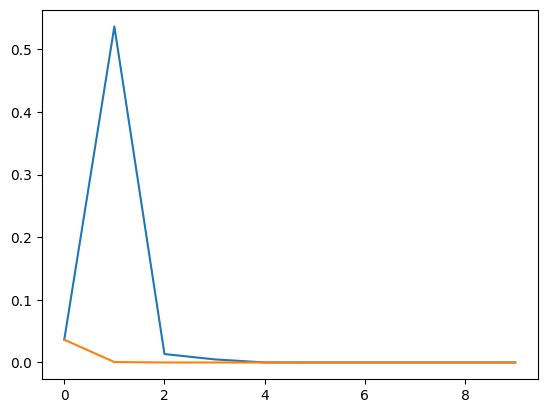

In [22]:
iterations = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
plt.plot(iterations, sec_err)
plt.plot(iterations, newt_err)

In [44]:
import numpy as np
import matplotlib.pyplot as plt
def f(x, t):
    return np.tan(x)-t
def df(x):
    return 1/(np.cos(x)**2) 

def newt2(x0, target, t, maxIters=10 ): 
    x = x0
    iter = 0
    to_plot = []
    while iter < maxIters:
        to_plot.append(20*np.log10(abs((x-target)/target)))
        fx = f(x, t)
        dfx = df(x)
        x = x - fx / dfx
        iter += 1
    return to_plot

def secant_method2(x0, x1, target, t, maxIters=10):
    to_plot = []
    iter = 0
    while iter < maxIters:
        fx0 = f(x0, t)
        fx1 = f(x1, t)
        if fx1-fx0 == 0:
            for i in range(0, maxIters-iter):
                to_plot.append(to_plot[iter-1])
            break
        to_plot.append(20*np.log10(abs((x0-target)/target)))
        x_next = x1 - fx1 * (x1 - x0) / (fx1 - fx0)
        x0, x1 = x1, x_next
        iter += 1
    return to_plot

C:\Users\Brandon\AppData\Local\Temp\ipykernel_22308\1540527845.py:13: RuntimeWarning: divide by zero encountered in log10
  to_plot.append(20*np.log10(abs((x-target)/target)))


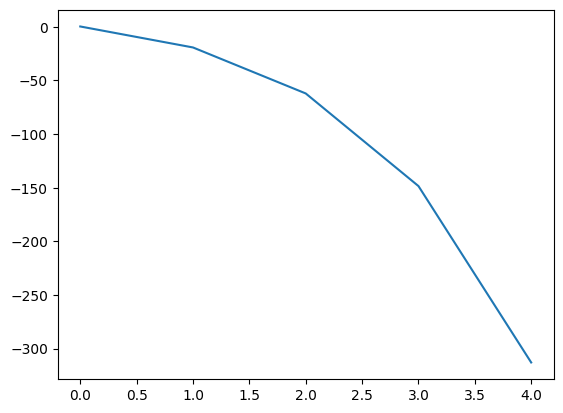

In [45]:
newt_log = newt2(0.5, np.arctan(0.25), 0.25)
plt.plot(iterations, newt_log)

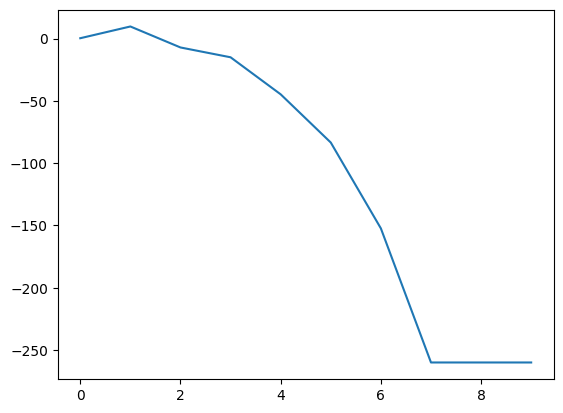

In [41]:
to_plot = secant_method2(0.5, 1, np.arctan(0.25), 0.25)
plt.plot(iterations, to_plot)

In [39]:
from PIL import Image
import numpy as np
image = Image.open("HK_first_cover_art.png").convert("RGB")
img_np = np.array(image)
r, g, b = img_np[:,:,0], img_np[:,:,1], img_np[:,:,2]
gray_array = 0.3 * r + 0.6 * g + 0.1 * b
gray_array = np.clip(gray_array, 0, 255).astype(np.uint8)
gray_img = Image.fromarray(gray_array)
resized_img = gray_img.resize((256, 256))
resized_img.show()
resized_array = np.array(resized_img)


In [64]:
column1 = resized_array[:, 1]
column2 = resized_array[:, 2]
mean_X1 = np.mean(column1)
mean_Y1 = np.mean(column2)
r1 = (np.sum((column1 - mean_X1) * (column2 - mean_Y1)))/(np.sqrt(np.sum((column1 - mean_X1)**2) * np.sum((column2 - mean_Y1)**2)))
print(r1)

column3 = resized_array[:, 3]
column4 = resized_array[:, 4]
mean_X2 = np.mean(column3)
mean_Y2 = np.mean(column4)
r2 = (np.sum((column3 - mean_X2) * (column4 - mean_Y2)))/(np.sqrt(np.sum((column3 - mean_X2)**2) * np.sum((column4 - mean_Y2)**2)))
print(r2)

column5 = resized_array[:, 5]
column6 = resized_array[:, 6]
mean_X3 = np.mean(column5)
mean_Y3 = np.mean(column6)
r3 = (np.sum((column5 - mean_X3) * (column6 - mean_Y3)))/(np.sqrt(np.sum((column5 - mean_X3)**2) * np.sum((column6 - mean_Y3)**2)))
print(r3)


0.9935463469431451
0.9931591567386359
0.9900558003770987


In [71]:
resized_array.shape

(256, 256)

In [76]:
compressed = np.zeros((128, 256))
index1 = 0
index2 = range(0, 256, 2)
for i in index2:
    compressed[index1] = resized_array[i]
    index1 += 1


In [86]:
decompressed = np.zeros((256,256))
index1 = 0
index2 = 0
for row in compressed:
    decompressed[index1] = compressed[index2]
    index1 += 1
    decompressed[index1] = compressed[index2]
    index1 += 1
    index2 += 1

In [90]:
new_img = Image.fromarray(decompressed)
new_img.show()

In [94]:
np.linalg.norm(resized_img) - np.linalg.norm(decompressed)

np.float64(30.624421492397232)